# Walmart : prédire les ventes hebdomadaires

**Contexte**  
Le service marketing de Walmart veut comprendre comment les ventes hebdomadaires d'un magasin dépendent d'indicateurs économiques (température, prix du carburant, CPI, chômage) et du calendrier, afin de mieux planifier ses campagnes.

**Objectif**  
Construire un modèle de régression qui estime `Weekly_Sales` avec la meilleure précision possible, et identifier les variables qui comptent vraiment.

**Données**  
Jeu personnalisé fourni pour le projet (150 lignes, 8 colonnes), dérivé d'une compétition Kaggle.

**Etapes du projet**
1. Imports et configuration
2. Exploration et préparation des données
3. Baseline : régression linéaire
4. Limiter le surapprentissage : Ridge et Lasso
5. Conclusion et limites


## 1. Imports et configuration

La cellule suivante importe les bibliothèques et fixe les paramètres.

In [105]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, RepeatedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")  # avertissements bénins (ex. magasin absent d'un pli de validation croisée)

RANDOM_STATE = 42

# Chemins relatifs : le notebook est dans notebooks/, les données dans data/
DATA_PATH = next(p for p in [Path("../data/Walmart_Store_sales.csv"), Path("data/Walmart_Store_sales.csv")] if p.exists())
FIG_DIR = DATA_PATH.parent.parent / "assets" / "images"

# Colonnes du modèle
ECO_COLS = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]
NUM_COLS = ECO_COLS + ["Year", "Month", "Day"]
CAT_COLS = ["Store", "Holiday_Flag"]

# Validation croisée répétée : 5 plis x 10 répétitions (plus stable qu'un seul découpage sur peu de données)
CV_SPLITTER = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

BLUE, ORANGE, GREEN = "#2f6fdc", "#f28c28", "#2a9d6f"

### Fonctions utilitaires

Quatre fonctions évitent de répéter du code :

- `show_fig` affiche et enregistre une figure ;
- `make_model` construit un **Pipeline** : prétraitement + modèle ;
- `evaluate_model` calcule les métriques d'un modèle ;
- `feature_names` récupère les noms des colonnes après prétraitement.

Le prétraitement (imputation, normalisation, encodage) apprend des valeurs à partir des données (médiane, moyenne, modalités). Intégré au Pipeline, il est ré-ajusté uniquement sur les données d'entraînement de chaque pli de validation croisée : aucune information du jeu de validation ou de test ne « fuit » vers l'apprentissage.

**Preprocessing**
- Numériques : valeurs manquantes remplacées par la **médiane**, puis **standardisation** (moyenne 0, écart-type 1). Elle met les variables à la même échelle, ce qui est indispensable pour Ridge et Lasso et permet de comparer les coefficients.
- Catégorielles (`Store`, `Holiday_Flag`) : modalité la plus fréquente, puis **one-hot encoding** avec `drop="first"` : une modalité sert de référence, ce qui évite des colonnes redondantes.

**Métriques**
- **R²** : part de la variance des ventes expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne, en dessous = moins bien que la moyenne).
- **RMSE** : racine de l'erreur quadratique moyenne, en dollars (pénalise les grosses erreurs).
- **MAPE** : erreur relative moyenne, en %.

In [106]:
def show_fig(fig, filename, width=900, height=450):
    """Affiche une figure Plotly et l'enregistre en PNG."""
    fig.update_layout(template="plotly_white", width=width, height=height, margin=dict(l=60, r=30, t=70, b=50))
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    try:
        png = fig.to_image(format="png", scale=2)  # nécessite kaleido
        (FIG_DIR / f"{filename}.png").write_bytes(png)
        display(Image(png))
    except Exception:
        fig.show()


def make_model(
        estimator, 
        num_cols=NUM_COLS, 
        cat_cols=CAT_COLS
    ):
    
    """Pipeline = prétraitement + modèle. Le prétraitement est ré-ajusté à chaque pli de validation croisée."""
    
    transformers = []
    
    if num_cols:
        transformers.append(("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                              ("scaler", StandardScaler())]), num_cols))
    if cat_cols:
        transformers.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                              ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore",
                                                                       sparse_output=False))]), cat_cols))
    preprocessor = ColumnTransformer(transformers, verbose_feature_names_out=False)
    return Pipeline([("preprocessor", preprocessor), ("model", estimator)])


def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    """Entraine le modèle sur le train et renvoie ses métriques (train, test, validation croisée)."""
    
    model.fit(X_train, y_train)
    
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    
    cv = cross_validate(model, X_train, y_train, cv=CV_SPLITTER,
                        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
    
    return {
        "Modèle": name,
        "R² train": r2_score(y_train, pred_train),
        "R² test": r2_score(y_test, pred_test),
        "R² CV": cv["test_r2"].mean(),
        "RMSE train": root_mean_squared_error(y_train, pred_train),
        "RMSE test": root_mean_squared_error(y_test, pred_test),
        "RMSE CV": -cv["test_rmse"].mean(),
        "MAPE test (%)": 100 * mean_absolute_percentage_error(y_test, pred_test),
    }


def feature_names(model):
    """Noms des colonnes après prétraitement (on retire le suffixe '.0' des modalités)."""
    return [n.removesuffix(".0") for n in model.named_steps["preprocessor"].get_feature_names_out()]


ROUND = {"R² train": 3, "R² test": 3, "R² CV": 3, "RMSE train": 0, "RMSE test": 0, "RMSE CV": 0, "MAPE test (%)": 1}


## 2. Exploration et préparation des données
### 2.1 Aperçu

On regarde la taille du jeu de données, quelques lignes et les statistiques de base.

In [107]:
df_raw = pd.read_csv(DATA_PATH)

print(f"{df_raw.shape[0]} lignes, {df_raw.shape[1]} colonnes")
display(df_raw.head())
display(df_raw.describe().round(2))

150 lignes, 8 colonnes


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,6.0,18-02-2011,1572117.54,NaN,59.61,3.045,214.777523,6.858
1,13.0,25-03-2011,1807545.43,0.0,42.38,3.435,128.616064,7.470
2,17.0,27-07-2012,NaN,0.0,NaN,NaN,130.719581,5.936
3,11.0,NaN,1244390.03,0.0,84.57,NaN,214.556497,7.346
4,6.0,28-05-2010,1644470.66,0.0,78.89,2.759,212.412888,7.092


,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,150.00,136.00,138.00,132.00,136.00,138.00,135.00
mean,9.87,1249535.83,0.08,61.40,3.32,179.90,7.60
std,6.23,647463.04,0.27,18.38,0.48,40.27,1.58
min,1.00,268929.03,0.00,18.79,2.51,126.11,5.14
25%,4.00,605075.72,0.00,45.59,2.85,131.97,6.60
50%,9.00,1261423.86,0.00,62.98,3.45,197.91,7.47
75%,15.75,1806386.20,0.00,76.34,3.71,214.93,8.15
max,20.00,2771397.17,1.00,91.65,4.19,226.97,14.31


### 2.2 Valeurs manquantes et préparation de base

**Observations**  
Toutes les colonnes sauf `Store` contiennent des valeurs manquantes (12 à 18 sur 150 lignes), y compris la cible `Weekly_Sales` (14 lignes) et la date (18 lignes).

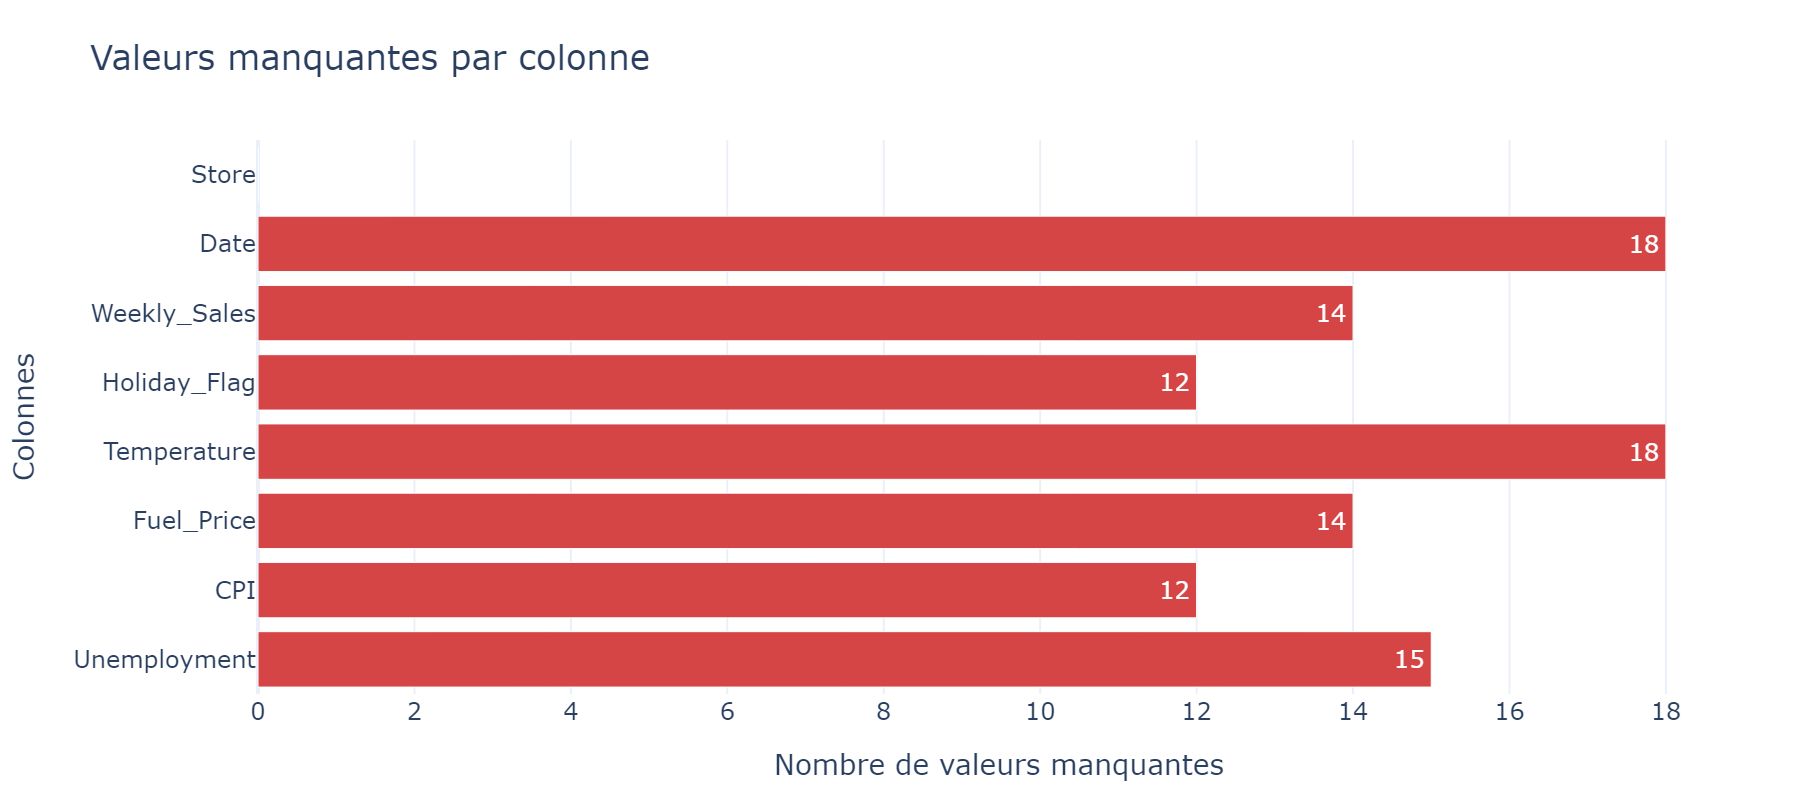

In [108]:
missing = df_raw.isna().sum()

fig = px.bar(x=missing.values, y=missing.index, orientation="h", text=missing.values,
             labels={"x": "Nombre de valeurs manquantes", "y": "Colonnes"},
             title="Valeurs manquantes par colonne", color_discrete_sequence=["#d64545"])

fig.update_yaxes(autorange="reversed")

show_fig(fig, "fig_01_valeurs_manquantes", height=400)

**Choix méthodologiques**
1. **Cible manquante** : Nous supprimons les lignes concernées. On n'impute pas la cible, car cela introduirait un biais dans les prédictions.
2. **Date** : Nous la remplacerons par `Year`, `Month` et `Day`. Le jour de la semaine est constant (toutes les dates sont des vendredis) : il n'apporte aucune information. Les dates invalides ou absentes donnent des valeurs manquantes, imputées plus tard dans le Pipeline.

In [109]:
# 1) Cible manquante : on supprime les lignes (jamais d'imputation sur la cible)
df = df_raw.dropna(subset=["Weekly_Sales"]).copy()
print(f"Lignes : {len(df_raw)} -> {len(df)}")

# 2) Variables issues de la date (les dates invalides deviennent NaN, imputées plus tard)
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
df["Year"], df["Month"], df["Day"] = df["Date"].dt.year, df["Date"].dt.month, df["Date"].dt.day

print("Jours de semaine présents :", sorted(df["Date"].dt.dayofweek.dropna().unique()), "(4 = vendredi)")

df = df.drop(columns="Date")  # le jour de semaine est constant : inutile, la date est remplacée par Year/Month/Day
df["Store"] = df["Store"].astype(int)
display(df.head())

Lignes : 150 -> 136
Jours de semaine présents : [np.float64(4.0)] (4 = vendredi)


,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Day
0,6,1572117.54,NaN,59.61,3.045,214.777523,6.858,2011.0,2.0,18.0
1,13,1807545.43,0.0,42.38,3.435,128.616064,7.470,2011.0,3.0,25.0
3,11,1244390.03,0.0,84.57,NaN,214.556497,7.346,NaN,NaN,NaN
4,6,1644470.66,0.0,78.89,2.759,212.412888,7.092,2010.0,5.0,28.0
5,4,1857533.70,0.0,NaN,2.756,126.160226,7.896,2010.0,5.0,28.0


### 2.3 Exploration

On explore les 136 lignes dont la cible est connue : distribution des ventes, ventes par magasin et selon les jours fériés, relations avec les variables économiques.

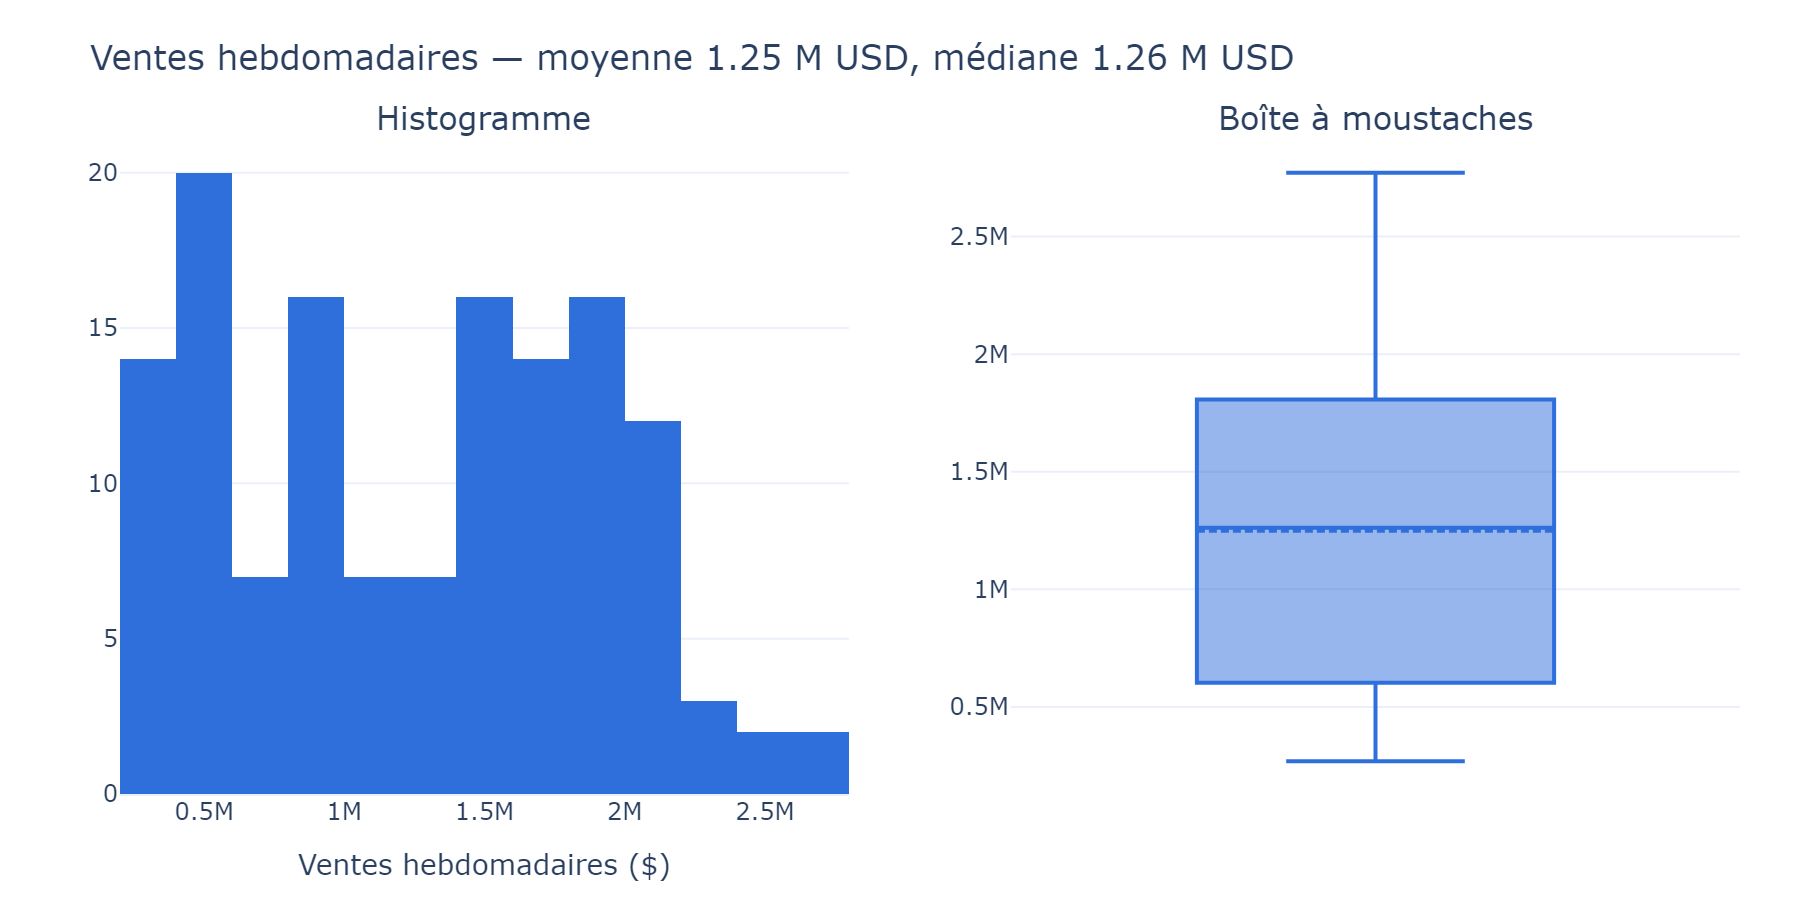

In [110]:
# Distribution de la cible
fig = make_subplots(rows=1, cols=2, subplot_titles=("Histogramme", "Boîte à moustaches"))

fig.add_trace(go.Histogram(x=df["Weekly_Sales"], nbinsx=25, marker_color=BLUE, showlegend=False), row=1, col=1)
fig.add_trace(go.Box(y=df["Weekly_Sales"], name="", marker_color=BLUE, boxmean=True, showlegend=False), row=1, col=2)

fig.update_xaxes(title_text="Ventes hebdomadaires ($)", row=1, col=1)
fig.update_layout(title=f"Ventes hebdomadaires — moyenne {df['Weekly_Sales'].mean()/1e6:.2f} M USD, "
                        f"médiane {df['Weekly_Sales'].median()/1e6:.2f} M USD")

show_fig(fig, "fig_02_distribution_ventes")

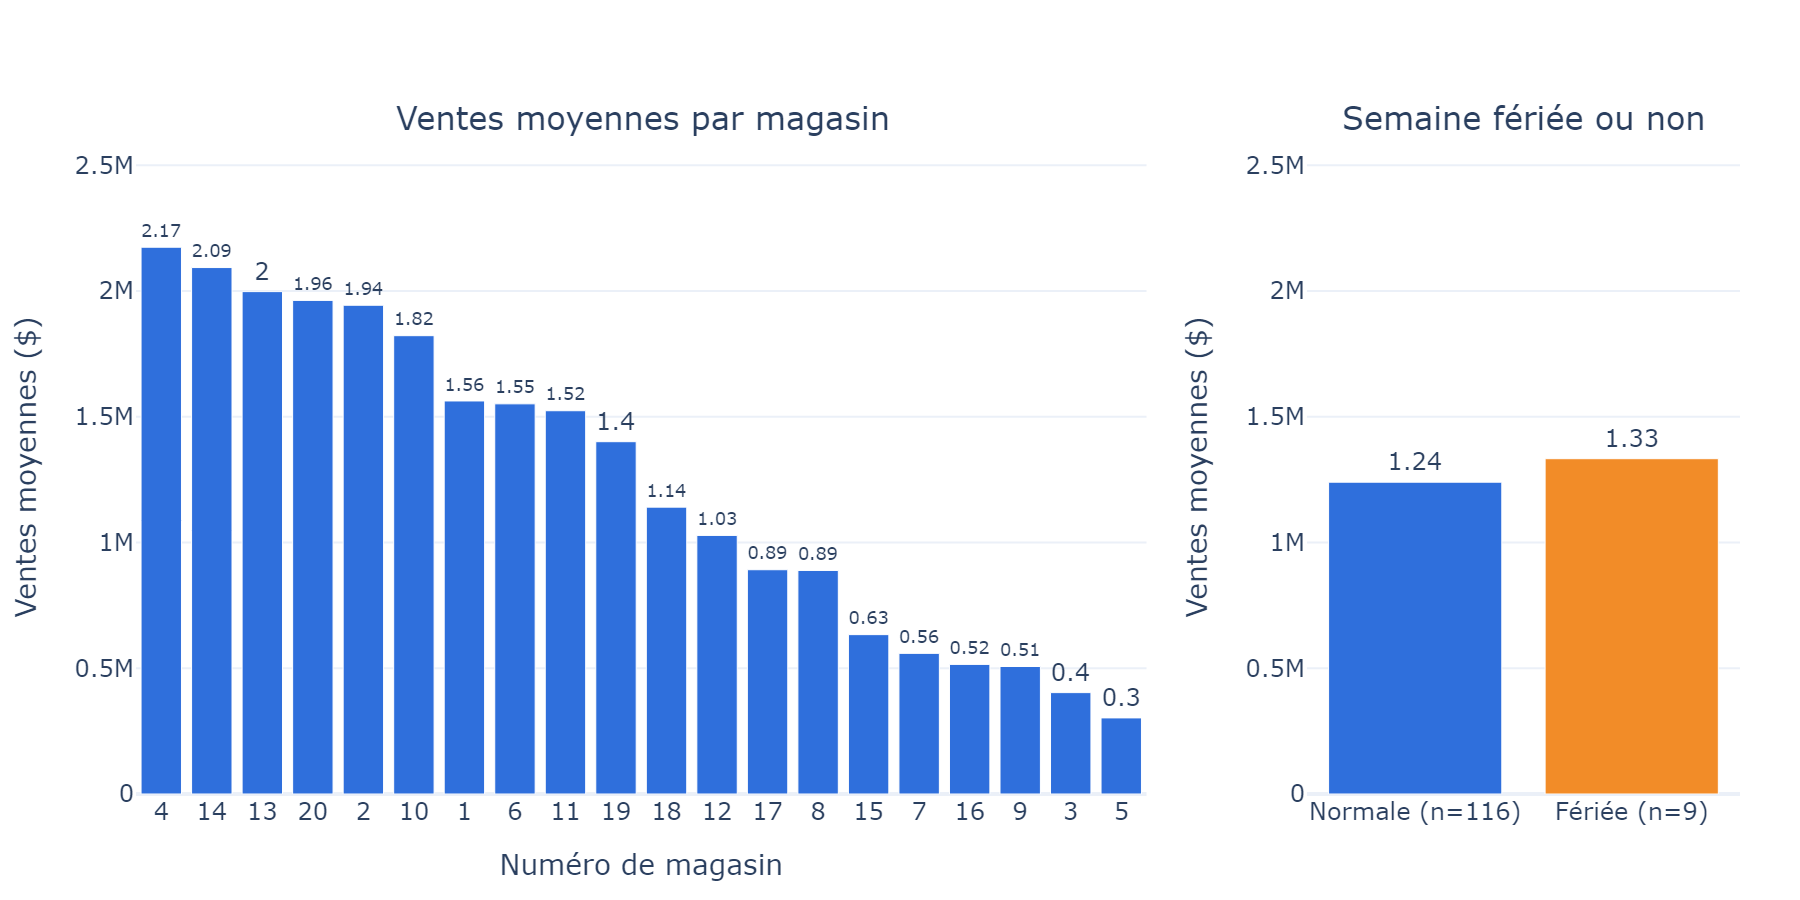

In [111]:
# Ventes par magasin et selon les jours fériés
by_store = df.groupby("Store")["Weekly_Sales"].mean().sort_values(ascending=False)
by_holiday = df.groupby("Holiday_Flag")["Weekly_Sales"].agg(["mean", "count"])

fig = make_subplots(rows=1, cols=2, column_widths=[0.7, 0.3],
                    subplot_titles=("Ventes moyennes par magasin", "Semaine fériée ou non"))

fig.add_trace(go.Bar(x=by_store.index.astype(str), y=by_store.values, marker_color=BLUE,
                     text=(by_store / 1e6).round(2), textposition="outside", showlegend=False), row=1, col=1)
fig.add_trace(go.Bar(x=[f"Normale (n={by_holiday.loc[0, 'count']})", f"Fériée (n={by_holiday.loc[1, 'count']})"],
                     y=by_holiday["mean"], marker_color=[BLUE, ORANGE],
                     text=(by_holiday["mean"] / 1e6).round(2), textposition="outside", showlegend=False), row=1, col=2)

fig.update_xaxes(title_text="Numéro de magasin", type="category", row=1, col=1)
fig.update_yaxes(title_text="Ventes moyennes ($)", range=[0, 2.6e6])

show_fig(fig, "fig_03_ventes_magasin_ferie")

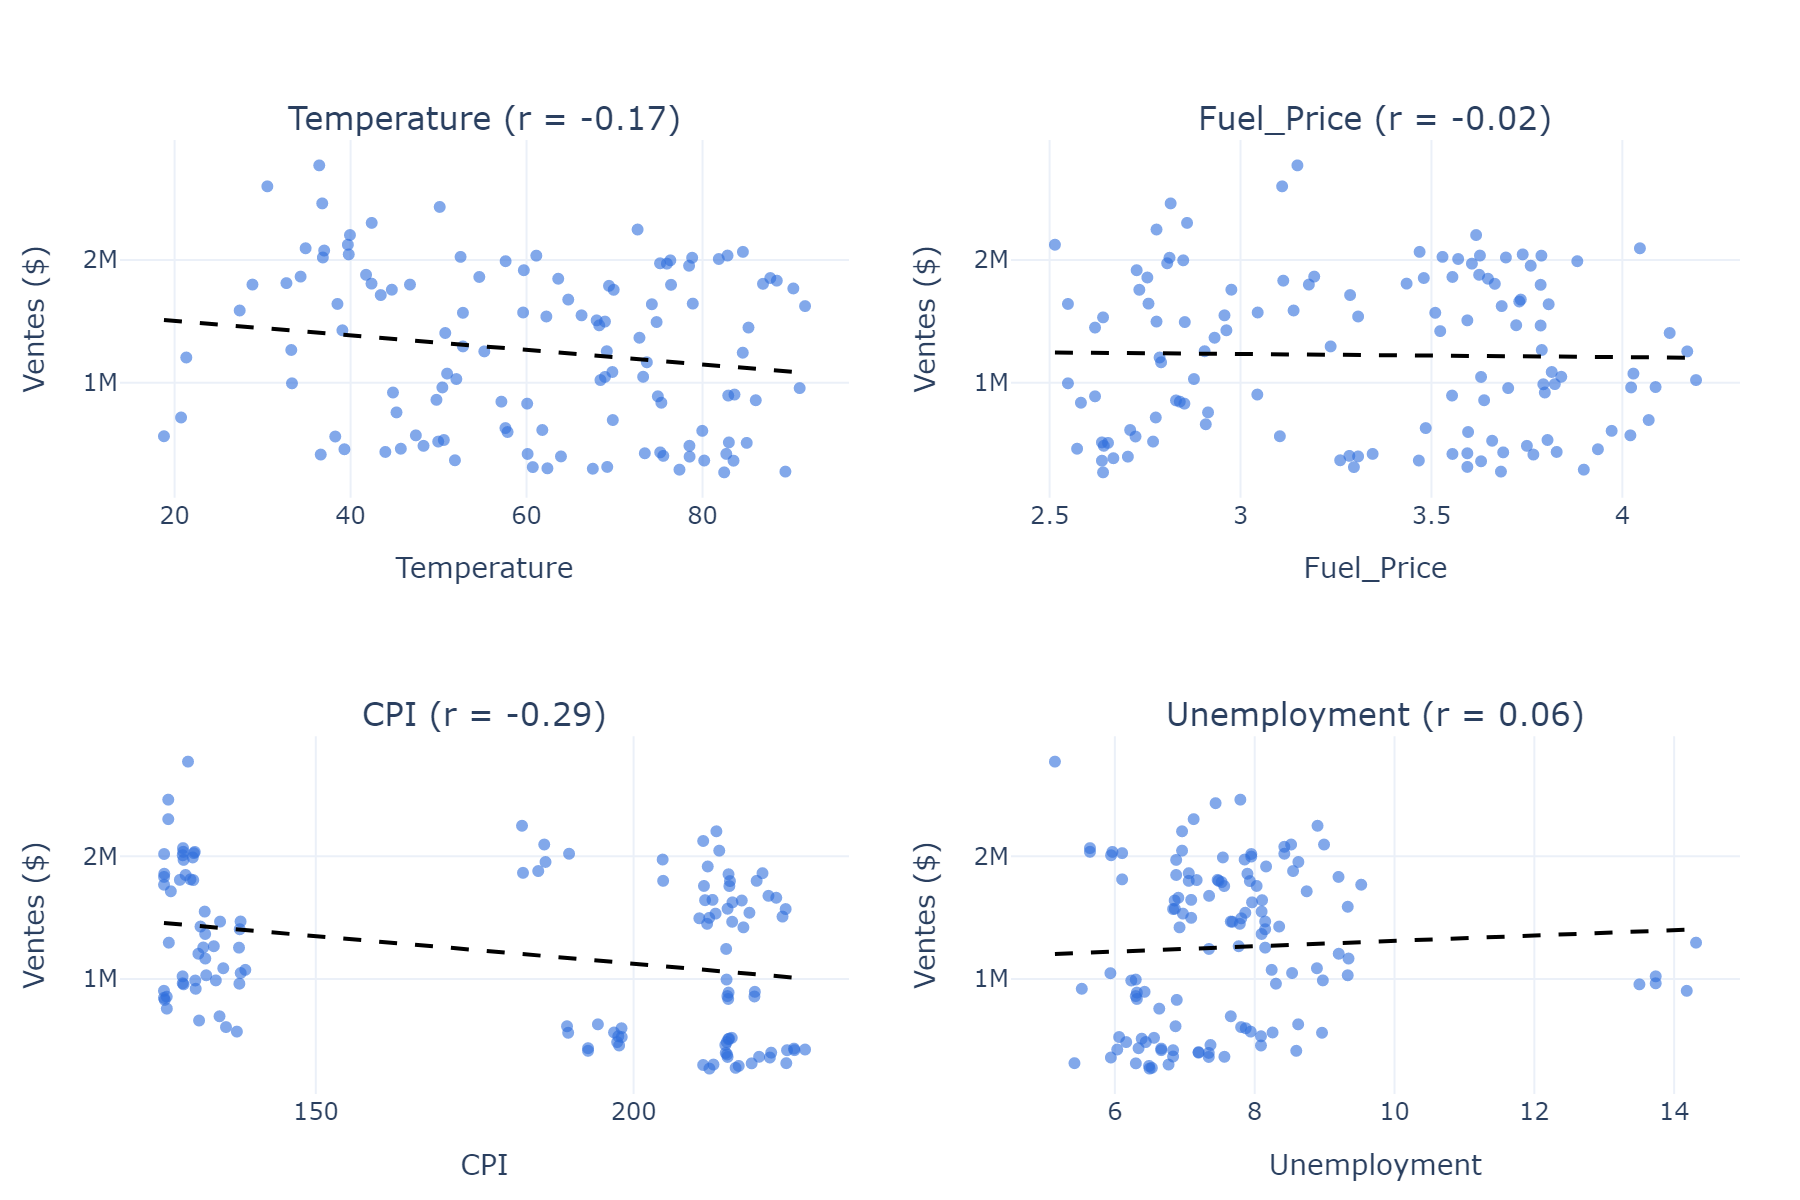

In [112]:
# Relation entre les ventes et chaque variable économique
fig = make_subplots(rows=2, cols=2, subplot_titles=[
    f"{c} (r = {df[['Weekly_Sales', c]].corr().iloc[0, 1]:.2f})" for c in ECO_COLS])

for i, col in enumerate(ECO_COLS):
    row, c = i // 2 + 1, i % 2 + 1
    d = df[[col, "Weekly_Sales"]].dropna()
    slope, intercept = np.polyfit(d[col], d["Weekly_Sales"], 1)
    xs = np.array([d[col].min(), d[col].max()])
    
    fig.add_trace(go.Scatter(x=d[col], y=d["Weekly_Sales"], mode="markers", marker=dict(color=BLUE, opacity=0.6),
                             showlegend=False), row=row, col=c)
    fig.add_trace(go.Scatter(x=xs, y=slope * xs + intercept, mode="lines", line=dict(color="black", dash="dash"),
                             showlegend=False), row=row, col=c)
    
    fig.update_xaxes(title_text=col, row=row, col=c)

fig.update_yaxes(title_text="Ventes ($)")

show_fig(fig, "fig_04_ventes_vs_variables", height=600)

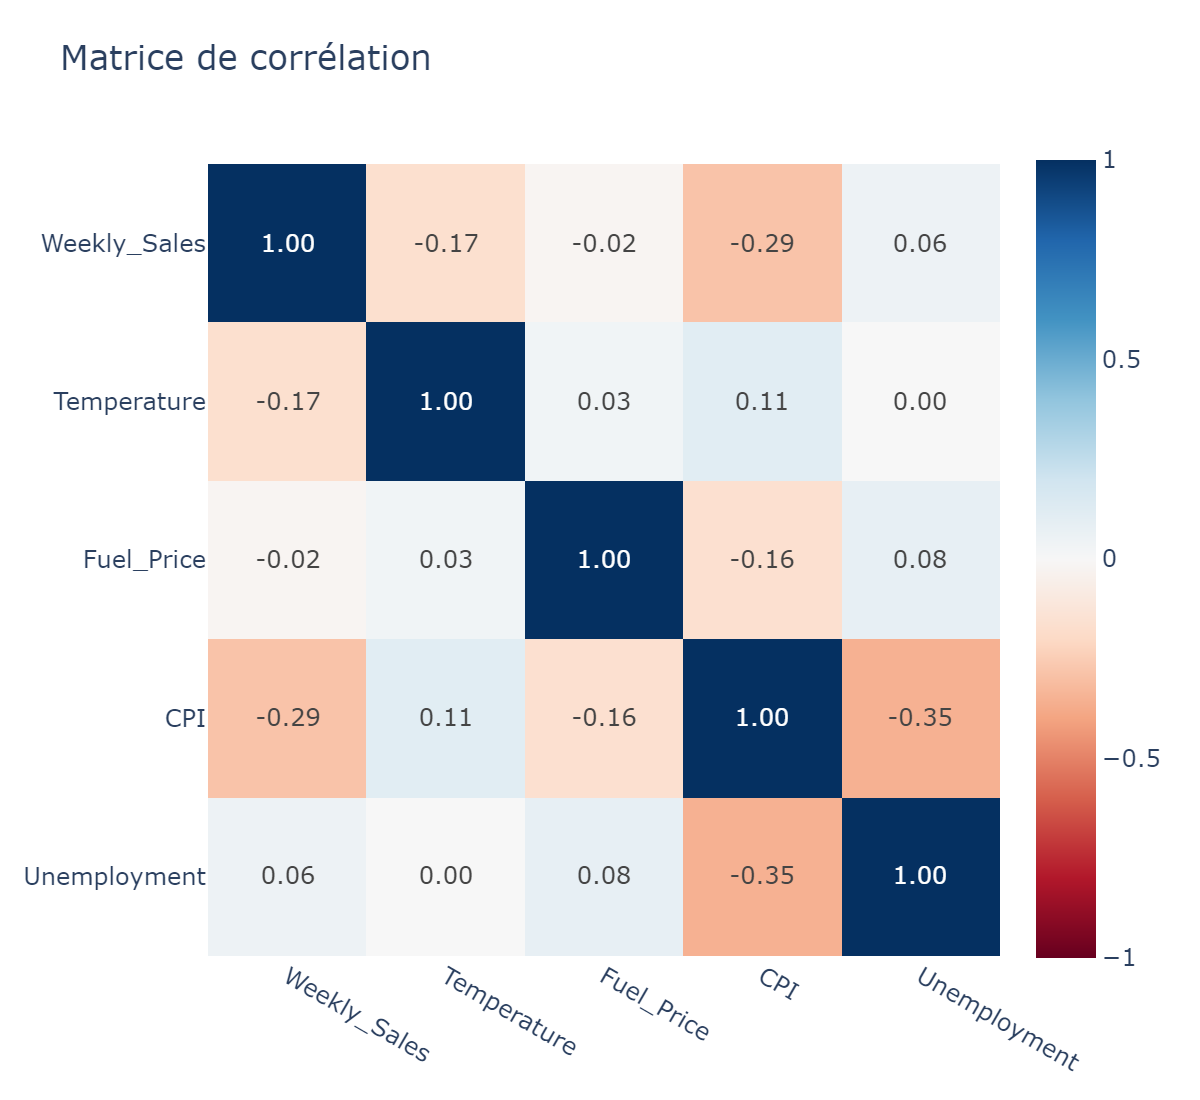

In [113]:
# Corrélations entre variables numériques
corr = df[["Weekly_Sales"] + ECO_COLS].corr()

fig = px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu", zmin=-1, zmax=1,
                title="Matrice de corrélation")

show_fig(fig, "fig_05_correlations", width=600, height=550)

**Observations et interprétations**
- Les ventes sont très dispersées (de 0,27 à 2,77 M$ par semaine) ; la moyenne (1,25 M$) et la médiane (1,26 M$) sont proches.
- Les magasins diffèrent fortement : de 0,3 à 2,2 M$ de ventes moyennes par semaine.
- Les semaines fériées ont des ventes un peu plus élevées en moyenne (1,33 M$ contre 1,24 M$), mais on n'en compte que 9 : l'écart est peu fiable.
- Les relations linéaires avec les variables économiques sont faibles (corrélations de −0,29 à +0,06). Ces variables sont peu corrélées entre elles (au plus 0,35 en valeur absolue, entre CPI et chômage).

**Le magasin explique presque tout le CPI et le chômage**

Pour chaque variable, on calcule la part de sa variance expliquée par le magasin : 1 − (variance à l'intérieur des magasins / variance totale). Elle vaut 99 % pour le CPI et 91 % pour le chômage, contre 30 % pour la température et 17 % pour le carburant.

Le CPI et le chômage varient donc surtout **d'un magasin à l'autre** (ce sont des indicateurs locaux quasi constants), pas d'une semaine à l'autre. Ils jouent le rôle d'identifiants de magasin, ce qui compliquera l'interprétation de leurs coefficients.

Part de variance expliquée par le magasin :
Temperature     30%
Fuel_Price      17%
CPI             99%
Unemployment    91%


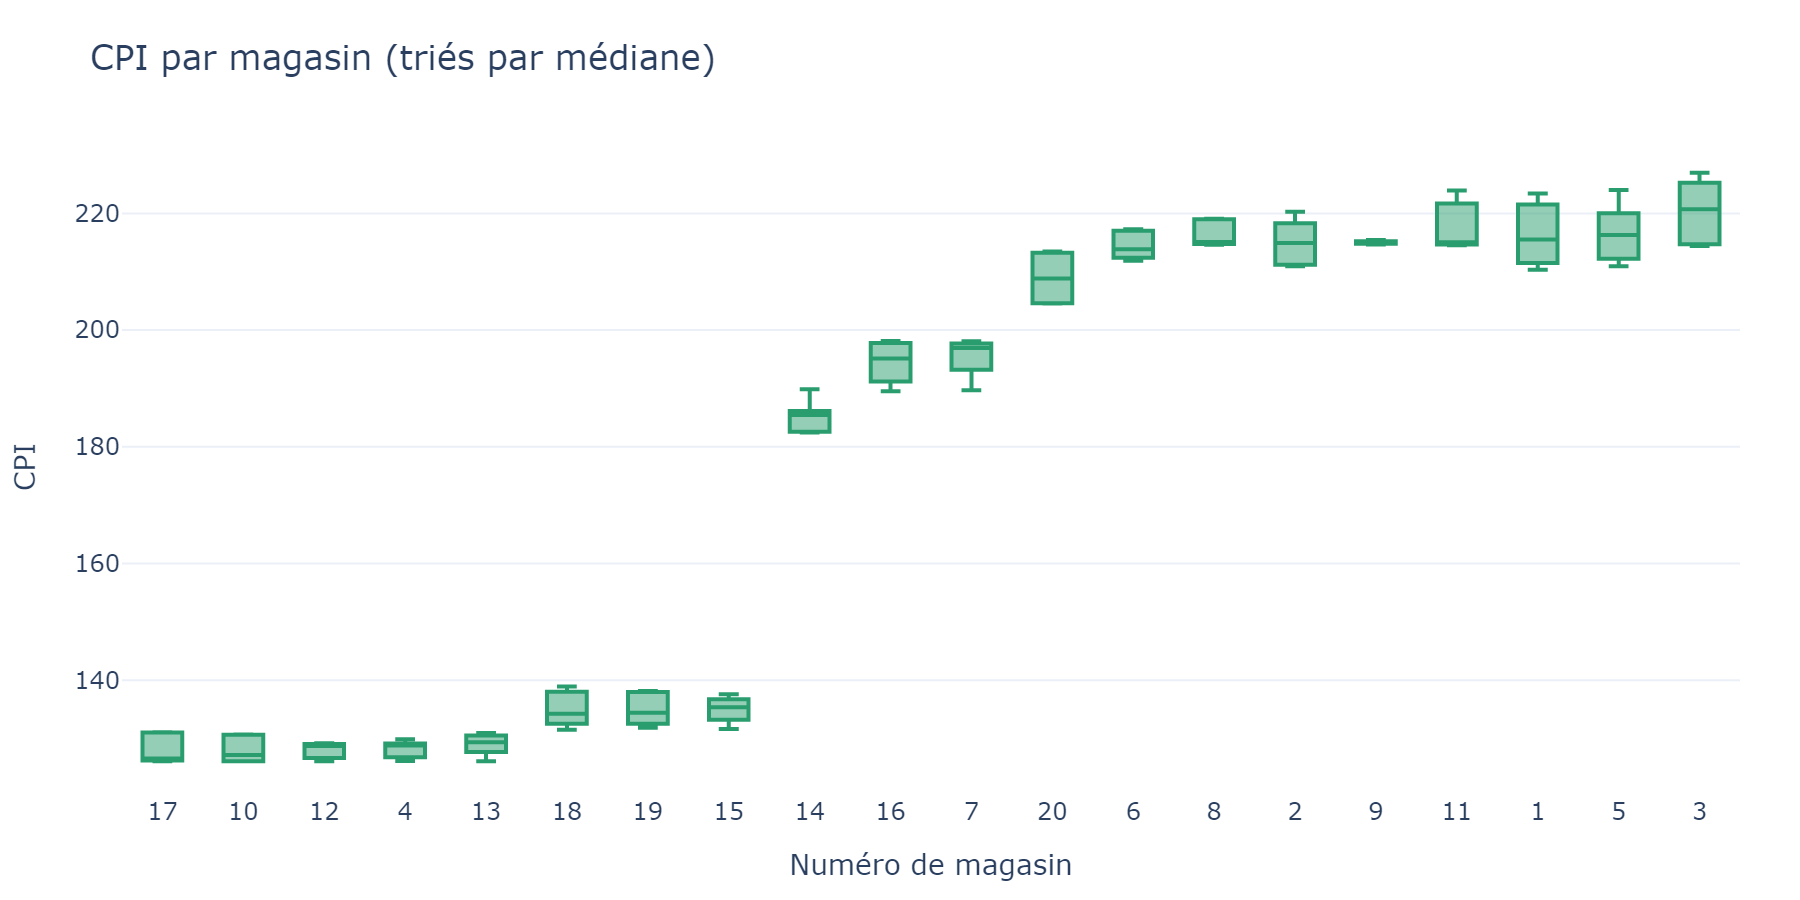

In [114]:
# Part de la variance de chaque variable expliquée par le magasin (sur les données brutes)
shares = {}

for col in ECO_COLS:
    d = df_raw[["Store", col]].dropna()
    store_mean = d.groupby("Store")[col].transform("mean")
    shares[col] = 1 - ((d[col] - store_mean) ** 2).sum() / ((d[col] - d[col].mean()) ** 2).sum()

print("Part de variance expliquée par le magasin :")
print(pd.Series(shares).map("{:.0%}".format).to_string())

order = df.groupby("Store")["CPI"].median().sort_values().index

fig = go.Figure([go.Box(y=df.loc[df["Store"] == s, "CPI"], name=str(s), marker_color=GREEN, showlegend=False)
                 for s in order])

fig.update_layout(title="CPI par magasin (triés par médiane)", xaxis_title="Numéro de magasin", yaxis_title="CPI")

show_fig(fig, "fig_06_cpi_par_magasin")

### 2.4 Gestion des valeurs aberrantes (règle des 3σ)

Nous appliquons la règle des 3σ : supprimer les lignes dont une variable parmi `Temperature`, `Fuel_Price`, `CPI` et `Unemployment` sort de l'intervalle [moyenne − 3σ ; moyenne + 3σ].

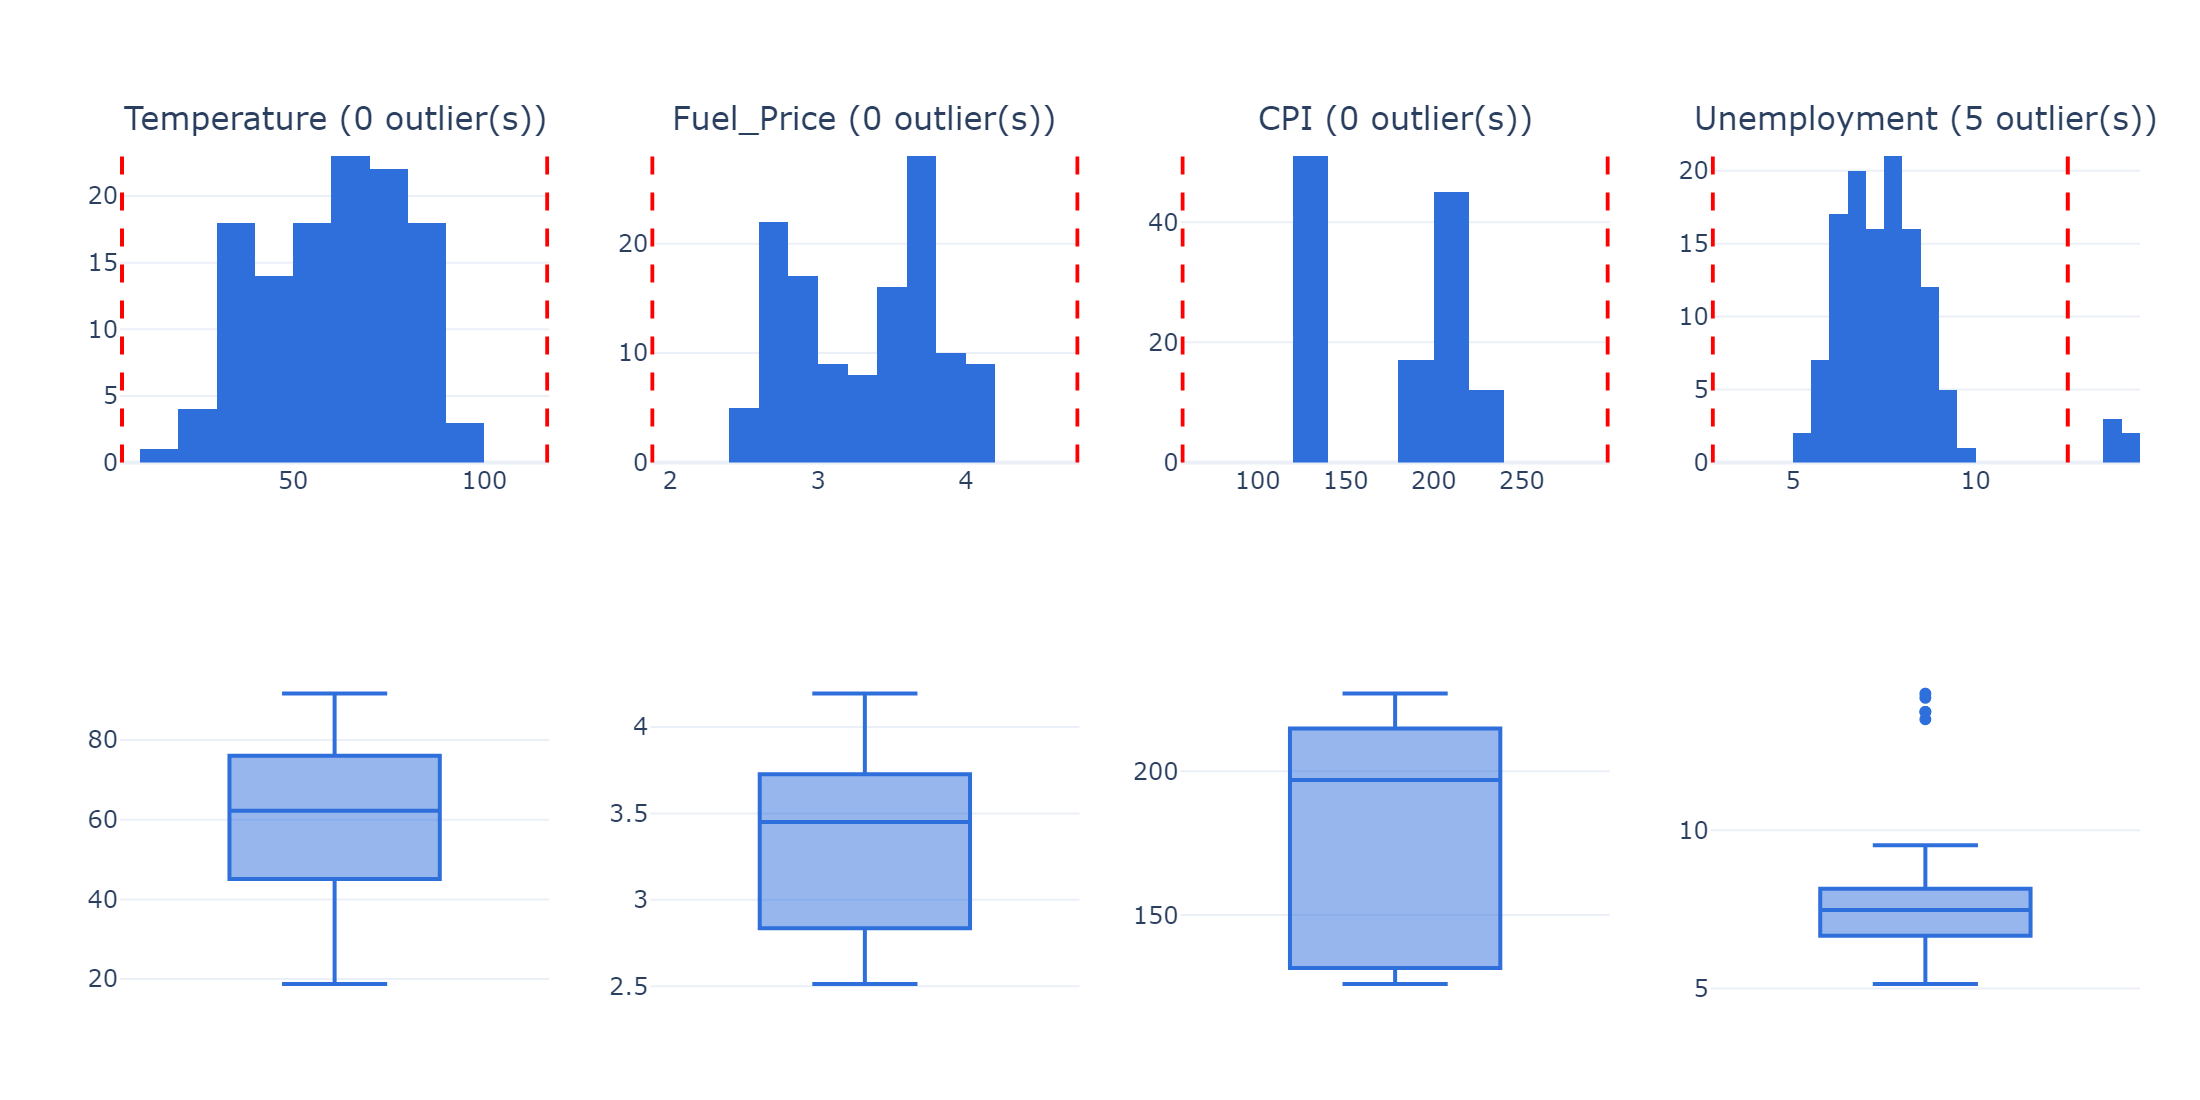

Magasin(s) concerné(s) par les outliers : [12]
Lignes : 136 -> 131


In [115]:
# Bornes [moyenne - 3 écarts-types ; moyenne + 3 écarts-types] pour les 4 variables économiques

bounds = {col: (df[col].mean() - 3 * df[col].std(), df[col].mean() + 3 * df[col].std()) for col in ECO_COLS}

is_outlier = pd.concat([(df[c] < low) | (df[c] > high) for c, (low, high) in bounds.items()], axis=1).any(axis=1)

fig = make_subplots(rows=2, cols=4, subplot_titles=[
    f"{c} ({((df[c] < bounds[c][0]) | (df[c] > bounds[c][1])).sum()} outlier(s))" for c in ECO_COLS])

for i, col in enumerate(ECO_COLS):
    fig.add_trace(go.Histogram(x=df[col], marker_color=BLUE, showlegend=False), row=1, col=i + 1)

    for b in bounds[col]:
        fig.add_vline(x=b, line=dict(color="red", dash="dash"), row=1, col=i + 1)

    fig.add_trace(go.Box(y=df[col], name="", marker_color=BLUE, showlegend=False), row=2, col=i + 1)

show_fig(fig, "fig_07_outliers", width=1100, height=550)

print("Magasin(s) concerné(s) par les outliers :", df.loc[is_outlier, "Store"].unique().tolist())

df_before_outliers = df.copy()
df = df[~is_outlier]

print(f"Lignes : {len(df_before_outliers)} -> {len(df)}")

**Résultat** : 5 lignes sont supprimées (136 → 131), **toutes du même magasin, le n°12**, à cause du chômage (13,5 à 14,3 % contre 9,5 % au maximum dans les autres magasins).

**Point d'attention.** Le magasin 12 disparaît donc entièrement du jeu de données. Son chômage est structurellement élevé : ce n'est pas du bruit de mesure. On applique néanmoins la règle de l'énoncé.

### 2.5 Séparation train / test

Nous utilisons 20 % des données de côté pour le test (`random_state`=42 fixé pour la reproductibilité). Le jeu de test ne contient que 27 lignes : ses métriques seront donc incertaines. Nous les complètons par une **validation croisée répétée** sur le jeu d'entraînement.

In [116]:
X = df.drop(columns="Weekly_Sales")
y = df["Weekly_Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Train : {len(X_train)} lignes | Test : {len(X_test)} lignes")

Train : 104 lignes | Test : 27 lignes


## 3. Baseline : régression linéaire
### 3.1 Modèles de référence

Un modèle n'a de valeur que s'il bat un point de repère simple. Nous en retenons trois :
- **Moyenne globale** : on prédit toujours la même valeur (aucune information utilisée) ;
- **Magasin seul** : on prédit la moyenne des ventes du magasin (régression linéaire sur la seule variable `Store`) ;
- **Sans le magasin** : régression linéaire avec toutes les variables sauf `Store`.

In [117]:
rows = []

# Prédire la moyenne globale du train
rows.append(evaluate_model("Moyenne globale",
                           make_model(DummyRegressor(strategy="mean"), num_cols=[], cat_cols=["Store"]),
                           X_train, y_train, X_test, y_test))

# Régression sur le magasin seul = prédire la moyenne des ventes du magasin
rows.append(evaluate_model("Magasin seul",
                           make_model(LinearRegression(), num_cols=[], cat_cols=["Store"]),
                           X_train, y_train, X_test, y_test))

# Toutes les variables SAUF le magasin
rows.append(evaluate_model("Sans le magasin",
                           make_model(LinearRegression(), cat_cols=["Holiday_Flag"]),
                           X_train, y_train, X_test, y_test))

pd.DataFrame(rows).set_index("Modèle").round(ROUND)

,R² train,R² test,R² CV,RMSE train,RMSE test,RMSE CV,MAPE test (%)
Modèle,,,,,,,
Moyenne globale,0.000,-0.032,-0.069,669560.0,598753.0,674237.0,80.0
Magasin seul,0.957,0.925,0.927,138602.0,161621.0,170920.0,10.9
Sans le magasin,0.130,-0.147,-0.172,624677.0,631112.0,701443.0,84.1


**Interprétation**
- La moyenne globale ne prédit rien : R² proche de 0 et erreur relative de 80 %.
- Le **magasin seul** suffit à obtenir un R² de 0,93 sur le test, un RMSE de 162 k$ et une erreur relative de 10,9 %. C'est une référence solide.
- **Sans le magasin**, le R² devient négatif (−0,17 en validation croisée) : le modèle est moins bon que la moyenne. Un modèle linéaire ne sait pas retrouver l'identité du magasin à partir du CPI ou du chômage, même si ces variables l'identifient en partie.

### 3.2 Régression linéaire complète

Nous ajoutons maintenant toutes les variables (économiques, date, jour férié) au magasin.

In [118]:
model_lr = make_model(LinearRegression())

rows.append(evaluate_model("Régression linéaire", model_lr, X_train, y_train, X_test, y_test))
results = pd.DataFrame(rows).set_index("Modèle")
display(results.round(ROUND))

gain = 1 - results.loc["Régression linéaire", "RMSE CV"] / results.loc["Magasin seul", "RMSE CV"]
print(f"RMSE en validation croisée : la régression linéaire fait {gain:.1%} mieux que le magasin seul.")

,R² train,R² test,R² CV,RMSE train,RMSE test,RMSE CV,MAPE test (%)
Modèle,,,,,,,
Moyenne globale,0.000,-0.032,-0.069,669560.0,598753.0,674237.0,80.0
Magasin seul,0.957,0.925,0.927,138602.0,161621.0,170920.0,10.9
Sans le magasin,0.130,-0.147,-0.172,624677.0,631112.0,701443.0,84.1
Régression linéaire,0.978,0.898,0.949,100071.0,188478.0,144608.0,15.1


RMSE en validation croisée : la régression linéaire fait 15.4% mieux que le magasin seul.


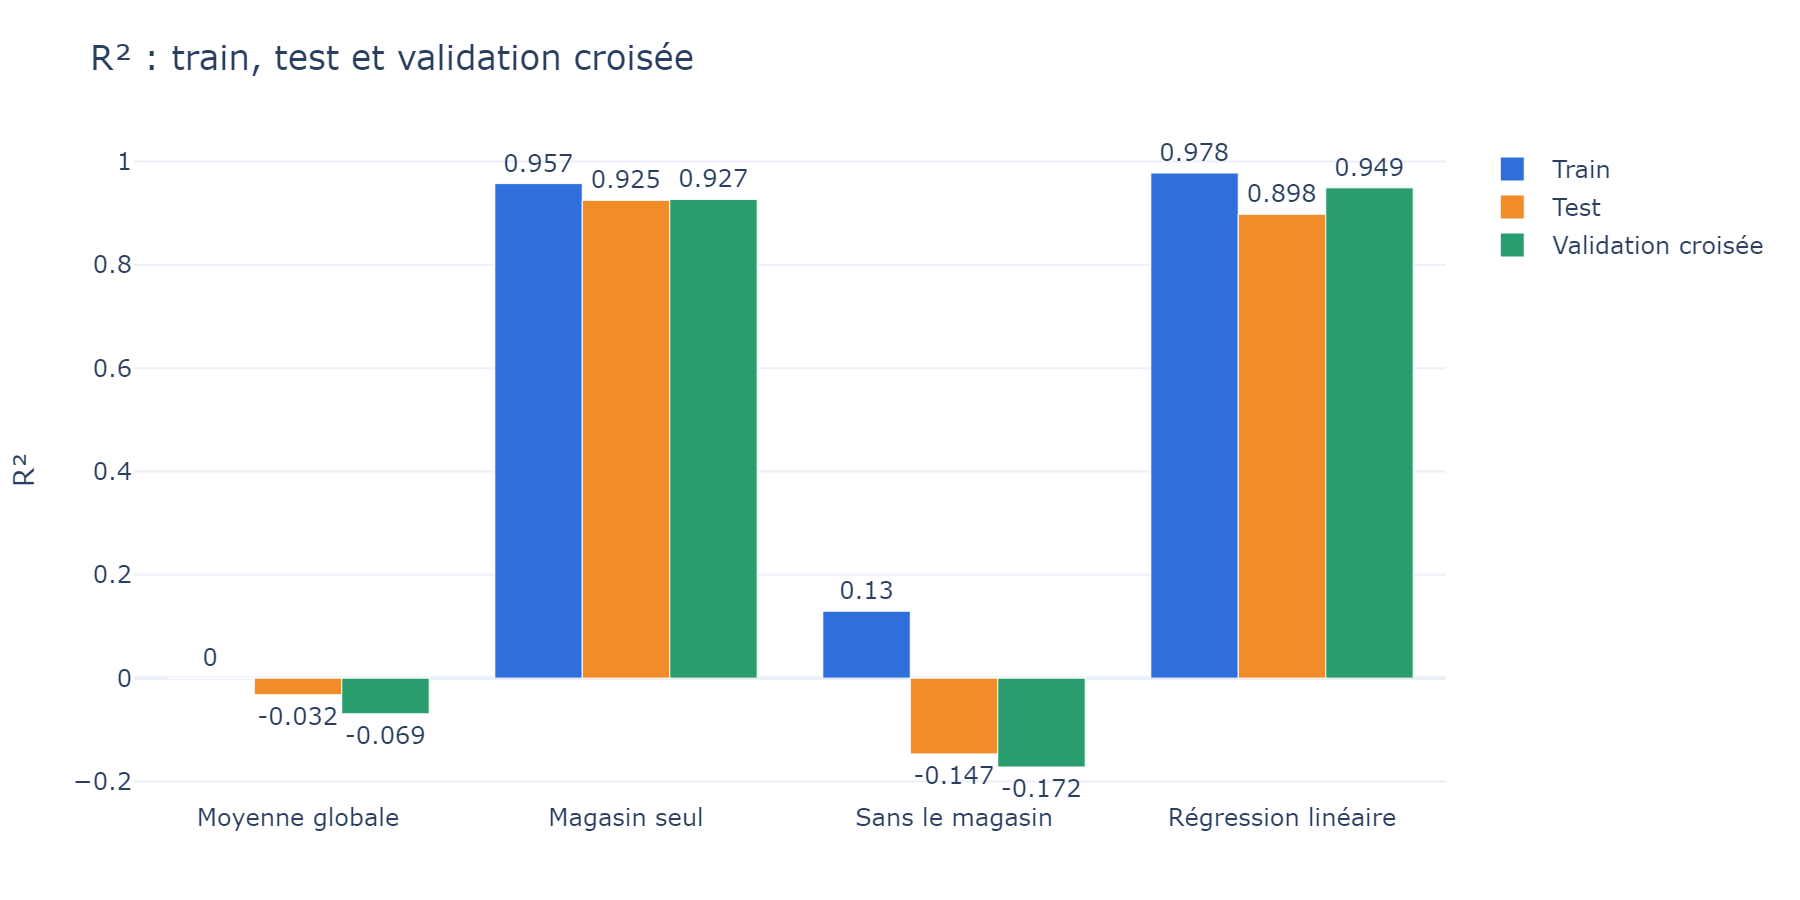

In [119]:
models = ["Moyenne globale", "Magasin seul", "Sans le magasin", "Régression linéaire"]

fig = go.Figure([go.Bar(name=lbl, x=models, y=results.loc[models, col], marker_color=color,
                        text=results.loc[models, col].round(3), textposition="outside")
                 for lbl, col, color in [("Train", "R² train", BLUE), ("Test", "R² test", ORANGE),
                                         ("Validation croisée", "R² CV", GREEN)]])
fig.update_layout(title="R² : train, test et validation croisée", barmode="group", yaxis_title="R²")

show_fig(fig, "fig_08_r2_modeles_base")

**Interprétation**
- **Surapprentissage modéré** : le R² passe de 0,978 sur le train à 0,898 sur le test.
- **En validation croisée**, la régression est meilleure que le magasin seul : RMSE de 144,6 k$ contre 170,9 k$ (−15 %).
- **Sur le jeu de test**, c'est l'inverse : 188 k$ contre 162 k$, et une erreur relative de 15,1 % contre 10,9 %.

Ces deux conclusions se contredisent : la section suivante cherche à savoir laquelle est la plus fiable.

### 3.3 Peut-on se fier au jeu de test ?

Avec 27 lignes, le résultat dépend beaucoup du tirage. Nous répétons donc la comparaison avec 50 découpages train/test différents, puis on regarde le poids de la plus grosse erreur du test.

In [120]:
# Le découpage train/test est-il représentatif ? On répète la comparaison avec 50 découpages différents.
def fit_rmse(model, X_a, y_a, X_b, y_b):
    return root_mean_squared_error(y_b, model.fit(X_a, y_a).predict(X_b))

gains = []

for seed in range(50):
    X_a, X_b, y_a, y_b = train_test_split(X, y, test_size=0.2, random_state=seed)
    rmse_lr = fit_rmse(make_model(LinearRegression()), X_a, y_a, X_b, y_b)
    rmse_store = fit_rmse(make_model(LinearRegression(), num_cols=[], cat_cols=["Store"]), X_a, y_a, X_b, y_b)
    gains.append(1 - rmse_lr / rmse_store)

gains = np.array(gains)

print(f"La régression bat le magasin seul sur {(gains > 0).sum()}/50 découpages "
      f"(gain médian {np.median(gains):.1%}, de {gains.min():.1%} à {gains.max():.1%}).")

# Poids de la plus grosse erreur sur le jeu de test (découpage utilisé dans ce notebook)
sq_err = (y_test - model_lr.predict(X_test)) ** 2
print(f"Une seule observation représente {sq_err.max() / sq_err.sum():.0%} de l'erreur quadratique du test.")

model_store = make_model(LinearRegression(), num_cols=[], cat_cols=["Store"]).fit(X_train, y_train)
sq_err_store = (y_test - model_store.predict(X_test)) ** 2
worst = sq_err.idxmax()
print(f"RMSE test sans cette observation : régression {np.sqrt(sq_err.drop(worst).mean()):,.0f} $ "
      f"| magasin seul {np.sqrt(sq_err_store.drop(worst).mean()):,.0f} $")

La régression bat le magasin seul sur 37/50 découpages (gain médian 10.2%, de -37.0% à 30.2%).
Une seule observation représente 36% de l'erreur quadratique du test.
RMSE test sans cette observation : régression 153,459 $ | magasin seul 155,659 $


**Interprétation**  
Selon le découpage, la régression fait de 37 % moins bien à 30 % mieux que le magasin seul : elle gagne dans 37 cas sur 50, avec un gain médian d'environ 10 %. De plus, une seule observation pèse 36 % de l'erreur quadratique du test : sans elle, les deux modèles sont à égalité (autour de 155 k$).

Le jeu de test de 27 lignes est donc **trop petit pour trancher**. La validation croisée, qui répète 50 évaluations, est plus fiable : la régression est modestement meilleure que le magasin seul, mais pas systématiquement.

### 3.4 Diagnostic des prédictions

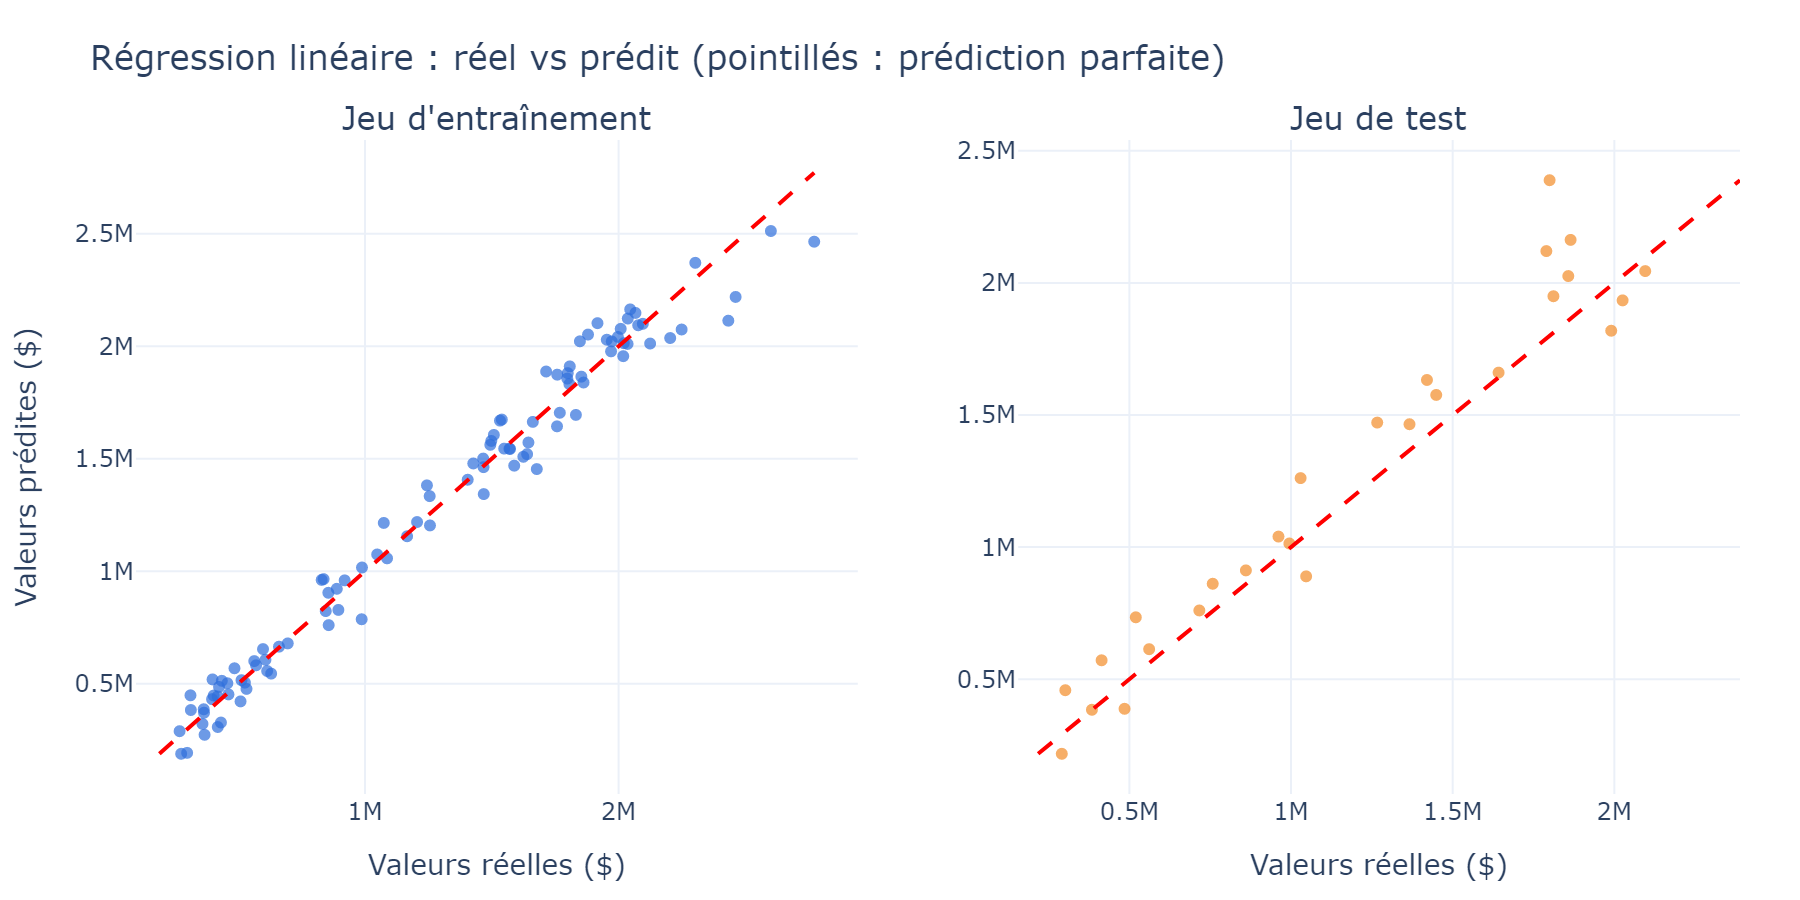

Résidu moyen : train -0 $ | test -98,280 $ (négatif = ventes surestimées)
Observation extrême du test : résidu -588,938 $ | résidu moyen du test sans elle : -79,408 $


In [121]:
pred_train, pred_test = model_lr.predict(X_train), model_lr.predict(X_test)
res_train, res_test = y_train - pred_train, y_test - pred_test

fig = make_subplots(rows=1, cols=2, subplot_titles=("Jeu d'entraînement", "Jeu de test"))

for i, (true, pred, color) in enumerate([(y_train, pred_train, BLUE), (y_test, pred_test, ORANGE)], start=1):
    fig.add_trace(go.Scatter(x=true, y=pred, mode="markers", marker=dict(color=color, opacity=0.7),
                             showlegend=False), row=1, col=i)
    lims = [min(true.min(), pred.min()), max(true.max(), pred.max())]
    fig.add_trace(go.Scatter(x=lims, y=lims, mode="lines", line=dict(color="red", dash="dash"),
                             showlegend=False), row=1, col=i)

    fig.update_xaxes(title_text="Valeurs réelles ($)", row=1, col=i)

fig.update_yaxes(title_text="Valeurs prédites ($)", col=1)
fig.update_layout(title="Régression linéaire : réel vs prédit (pointillés : prédiction parfaite)")

show_fig(fig, "fig_09_reel_vs_predit")

worst = res_test.abs().idxmax()
print(f"Résidu moyen : train {res_train.mean():,.0f} $ | test {res_test.mean():,.0f} $ (négatif = ventes surestimées)")
print(f"Observation extrême du test : résidu {res_test[worst]:,.0f} $ | "
      f"résidu moyen du test sans elle : {res_test.drop(worst).mean():,.0f} $")

**Interprétation**
- Sur le train, les points sont proches de la diagonale ; sur le test, ils sont plus dispersés, ce qui rejoint l'écart de R² vu en 3.2.
- Le résidu moyen du test est négatif (−98 k$) : le modèle surestime en moyenne les ventes.
- L'observation extrême identifiée en 3.3 (résidu de -589 k$) n'explique qu'une petite part de ce biais : sans elle, le résidu moyen reste de 79 k$. Avec 27 lignes, on ne peut pas dire si ce biais vient du tirage ou d'un défaut du modèle.

### 3.5 Interprétation des coefficients

In [122]:
coefs = pd.Series(model_lr.named_steps["model"].coef_, index=feature_names(model_lr))

print("Variables numériques (standardisées) et jour férié :")

display(coefs[NUM_COLS + ["Holiday_Flag_1"]].sort_values().round(0).to_frame("Coefficient ($)"))

print("Effet des magasins (écart par rapport au magasin de référence, le n°1) : "
      f"de {coefs.filter(like='Store_').min():,.0f} $ à {coefs.filter(like='Store_').max():,.0f} $")

Variables numériques (standardisées) et jour férié :


,Coefficient ($)
Unemployment,-70249.0
Temperature,-60428.0
Year,-47742.0
Day,-15135.0
Fuel_Price,-7468.0
CPI,48864.0
Holiday_Flag_1,51506.0
Month,67412.0


Effet des magasins (écart par rapport au magasin de référence, le n°1) : de -1,363,365 $ à 605,226 $


- Pour les variables numériques (standardisées), le coefficient est la **variation des ventes en dollars pour une hausse d'un écart-type** de la variable, les autres étant fixées.
- Pour le jour férié : variation entre une semaine normale (0) et une semaine fériée (1).
- Pour les magasins : écart par rapport au magasin de référence (le n°1).

Un coefficient seul ne dit pas s'il est fiable : avec 104 lignes, il changerait si l'on disposait d'autres semaines. Nous estimons son incertitude par **bootstrap** : nous refaisons l'apprentissage 300 fois sur des échantillons tirés **avec remise** dans le jeu d'entraînement, puis nous regardons l'intervalle qui contient 95 % des coefficients obtenus. Si cet intervalle contient 0, l'effet n'est pas distinguable de 0.

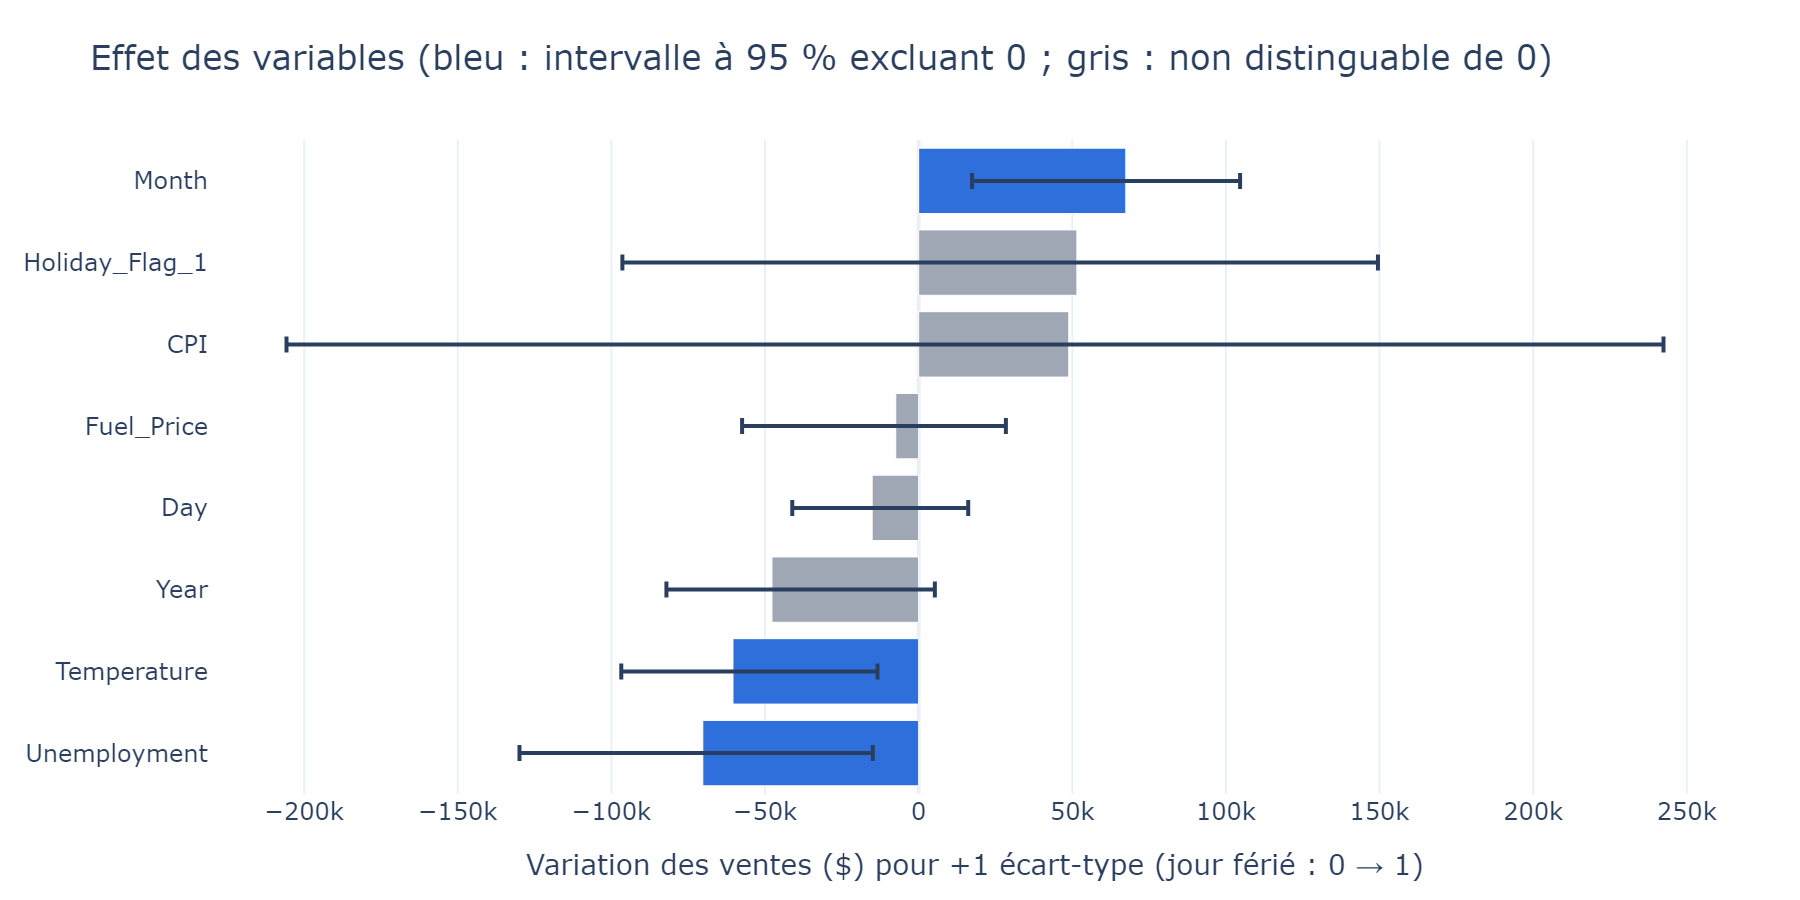

,Coefficient,IC 95 % bas,IC 95 % haut,Stable
Unemployment,-70249.0,-129915.0,-14930.0,True
Temperature,-60428.0,-96783.0,-13399.0,True
Year,-47742.0,-82091.0,5265.0,False
Day,-15135.0,-41134.0,16125.0,False
Fuel_Price,-7468.0,-57463.0,28386.0,False
CPI,48864.0,-205737.0,242407.0,False
Holiday_Flag_1,51506.0,-96426.0,149472.0,False
Month,67412.0,17372.0,104610.0,True


In [123]:
effect_names = NUM_COLS + ["Holiday_Flag_1"]

rng = np.random.default_rng(RANDOM_STATE)

boot = []

for _ in range(300):
    idx = rng.integers(0, len(X_train), len(X_train))  # tirage avec remise
    m = make_model(LinearRegression()).fit(X_train.iloc[idx], y_train.iloc[idx])
    boot.append(pd.Series(m.named_steps["model"].coef_, index=feature_names(m)).reindex(effect_names))
boot = pd.DataFrame(boot)

summary = pd.DataFrame({"Coefficient": coefs[effect_names],
                        "IC 95 % bas": boot.quantile(0.025), "IC 95 % haut": boot.quantile(0.975)})

summary["Stable"] = (summary["IC 95 % bas"] > 0) | (summary["IC 95 % haut"] < 0)

summary = summary.sort_values("Coefficient")

fig = go.Figure(go.Bar(
    x=summary["Coefficient"], y=summary.index, orientation="h",
    marker_color=[BLUE if s else "#a0a7b4" for s in summary["Stable"]],
    error_x=dict(type="data", symmetric=False, array=summary["IC 95 % haut"] - summary["Coefficient"],
                 arrayminus=summary["Coefficient"] - summary["IC 95 % bas"])))

fig.update_layout(title="Effet des variables (bleu : intervalle à 95 % excluant 0 ; gris : non distinguable de 0)",
                  xaxis_title="Variation des ventes ($) pour +1 écart-type (jour férié : 0 → 1)")

show_fig(fig, "fig_10_effets_bootstrap")

display(summary.round(0))

**Interprétation**
- **Effets stables** (intervalle à 95 % hors de 0) : la température (négatif), le chômage (négatif) et le mois (positif).
- **Effets non distinguables de 0** : CPI, carburant, jour férié, année et jour.
- Ces effets restent modestes (quelques dizaines de milliers de dollars), alors que les écarts entre magasins vont de −1,36 M$ à +0,61 M$.

**Point d'attention** « Stable » n''implique pas « causal ».

## 4. Limiter le surapprentissage : Ridge et Lasso

Ces deux modèles ajoutent à la régression une **pénalité** qui limite la taille des coefficients :
- **Ridge** (pénalité L2) réduit les coefficients ;
- **Lasso** (pénalité L1) peut en annuler certains.

L'hyperparamètre `alpha` règle la force de la pénalité : proche de 0, on retrouve la régression ordinaire ; très grand, le modèle devient plat.

### 4.1 Choix de alpha par validation croisée

Nous testons 40 valeurs de `alpha` avec `GridSearchCV`, en utilisant le même découpage de validation croisée que pour le tableau de résultats, ce qui rend les scores comparables. Le meilleur `alpha` est celui qui minimise le RMSE en validation croisée.

In [124]:
# On utilise le même découpeur de validation croisée que pour le tableau de résultats : les scores sont comparables
ridge_search = GridSearchCV(make_model(Ridge()), {"model__alpha": np.logspace(-3, 4, 40)},
                            cv=CV_SPLITTER, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

lasso_search = GridSearchCV(make_model(Lasso(max_iter=100_000)), {"model__alpha": np.logspace(-1, 5, 40)},
                            cv=CV_SPLITTER, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

print(f"Ridge : alpha optimal = {ridge_search.best_params_['model__alpha']:.3g} | RMSE CV = {-ridge_search.best_score_:,.0f} $")
print(f"Lasso : alpha optimal = {lasso_search.best_params_['model__alpha']:.3g} | RMSE CV = {-lasso_search.best_score_:,.0f} $")

Ridge : alpha optimal = 0.0273 | RMSE CV = 143,516 $
Lasso : alpha optimal = 492 | RMSE CV = 142,777 $


Courbes du RMSE selon `alpha` :

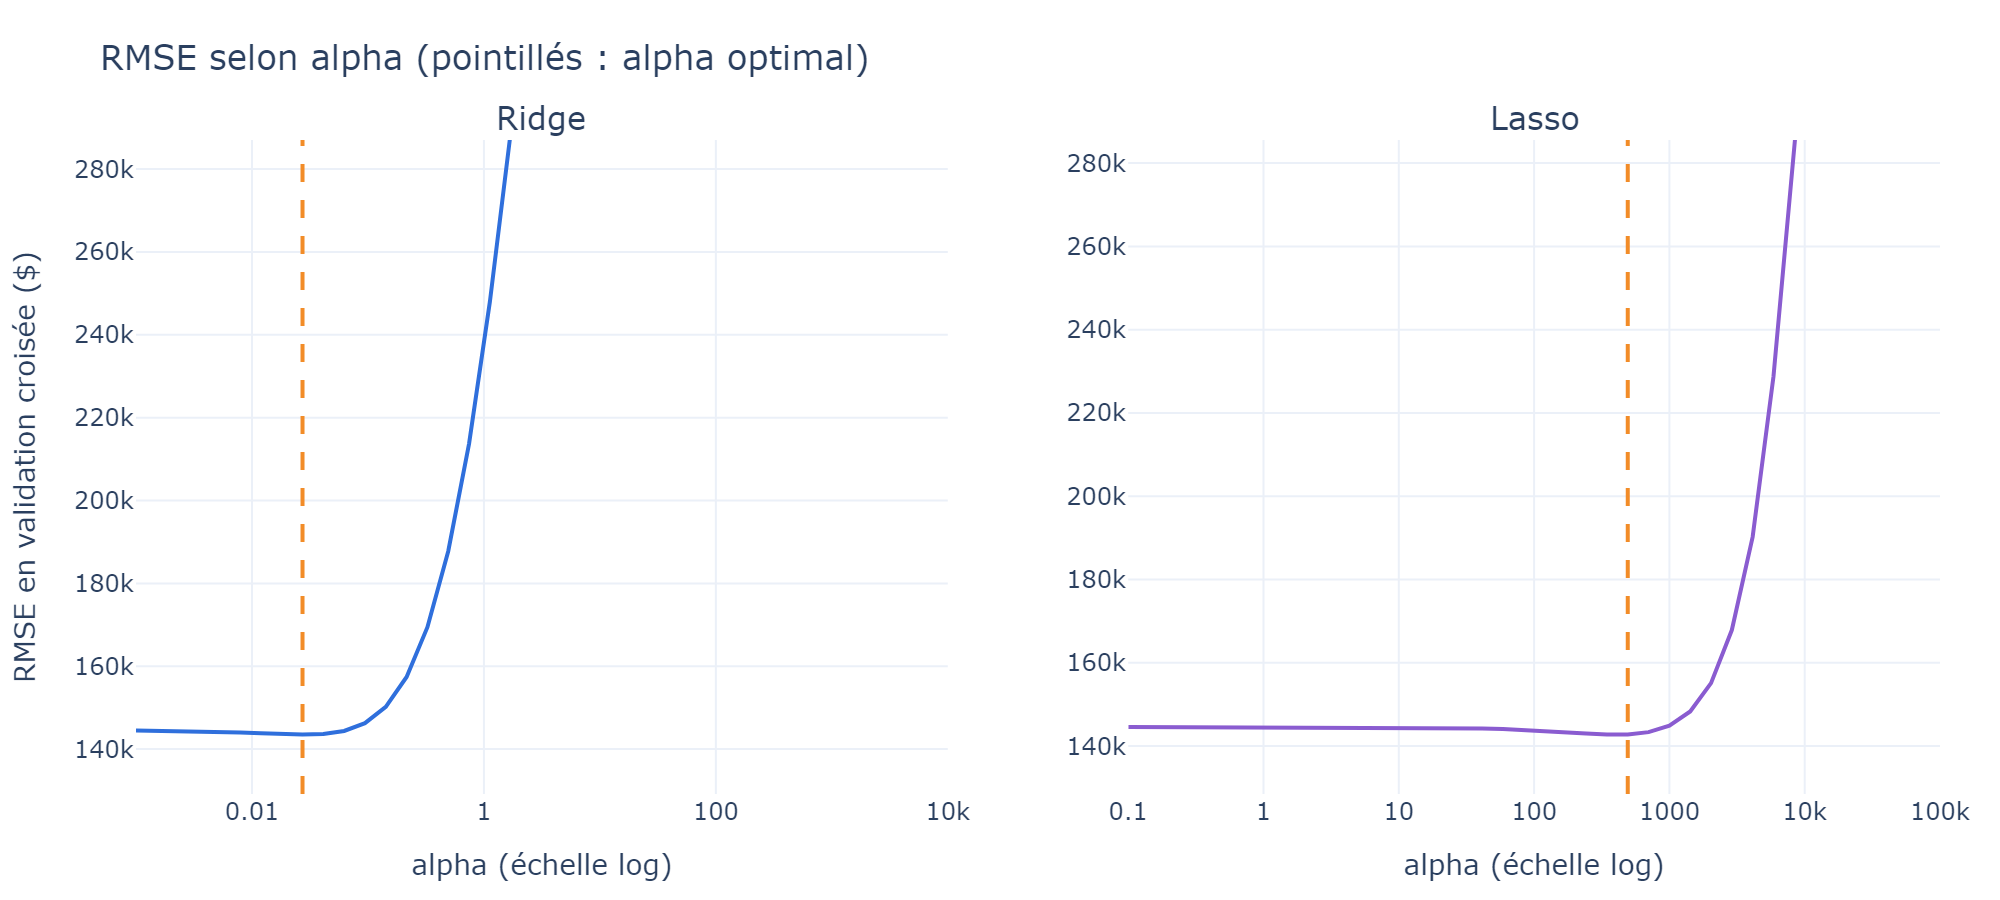

In [125]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Ridge", "Lasso"), horizontal_spacing=0.1)

for i, (search, color) in enumerate([(ridge_search, BLUE), (lasso_search, "#8a5cd0")], start=1):
    alphas = search.cv_results_["param_model__alpha"].astype(float)
    rmse, std = -search.cv_results_["mean_test_score"], search.cv_results_["std_test_score"]
    
    fig.add_trace(go.Scatter(x=alphas, y=rmse, mode="lines", line=dict(color=color), showlegend=False), row=1, col=i)
    fig.add_vline(x=search.best_params_["model__alpha"], line=dict(color=ORANGE, dash="dash"), row=1, col=i)
    
    fig.update_xaxes(title_text="alpha (échelle log)", type="log", row=1, col=i)
    fig.update_yaxes(range=[rmse.min() * 0.9, rmse.min() * 2], row=1, col=i)  # zoom sur la zone utile

fig.update_yaxes(title_text="RMSE en validation croisée ($)", col=1)

fig.update_layout(title="RMSE selon alpha (pointillés : alpha optimal)")

show_fig(fig, "fig_11_courbes_alpha", width=1000)

**Interprétation**
- Les courbes sont plates sur une grande plage d'`alpha` : le choix n'est pas critique. Au-delà, le modèle s'aplatit et l'erreur augmente fortement (l'axe est volontairement zoomé sur la zone utile).
- Le `alpha` optimal du Ridge est très petit : la pénalité est très faible.
- Le Lasso retient un `alpha` plus élevé (son échelle est différente) mais n'annule qu'un seul coefficient sur 26 (voir 4.3).

**Interprétation**
- **Ridge** : la courbe n'est plate que pour de très petites valeurs (`alpha` <= 0,05). Au-delà, l'erreur monte vite et dépasse celle du « magasin seul » dès `alpha` ≈ 0,5 à 1.
- **Lasso** : la courbe est plate sur une très large plage : le choix d'`alpha` n'est pas critique.
- Le `alpha` optimal du Ridge (0,027) est donc très petit : la pénalité est très faible et le modèle reste proche de la régression ordinaire.
- Le Lasso retient un `alpha` bien plus élevé (la pénalité L1 n'a pas la même échelle) mais n'annule qu'un seul coefficient sur 26 (voir 4.3).
- Quand `alpha` devient trop grand, l'erreur augmente fortement (l'axe est volontairement zoomé sur la zone utile).

### 4.2 Comparaison des modèles

In [126]:
rows.append(evaluate_model("Ridge", ridge_search.best_estimator_, X_train, y_train, X_test, y_test))
rows.append(evaluate_model("Lasso", lasso_search.best_estimator_, X_train, y_train, X_test, y_test))
results = pd.DataFrame(rows).set_index("Modèle")
compared = ["Magasin seul", "Régression linéaire", "Ridge", "Lasso"]
display(results.loc[compared].round(ROUND))

spread = results.loc[["Régression linéaire", "Ridge", "Lasso"], "RMSE CV"]
print(f"Écart de RMSE CV entre les trois modèles linéaires : {spread.max() / spread.min() - 1:.1%}")

,R² train,R² test,R² CV,RMSE train,RMSE test,RMSE CV,MAPE test (%)
Modèle,,,,,,,
Magasin seul,0.957,0.925,0.927,138602.0,161621.0,170920.0,10.9
Régression linéaire,0.978,0.898,0.949,100071.0,188478.0,144608.0,15.1
Ridge,0.978,0.899,0.950,100347.0,187207.0,143516.0,15.0
Lasso,0.977,0.902,0.950,100915.0,184476.0,142777.0,15.2


Écart de RMSE CV entre les trois modèles linéaires : 1.3%


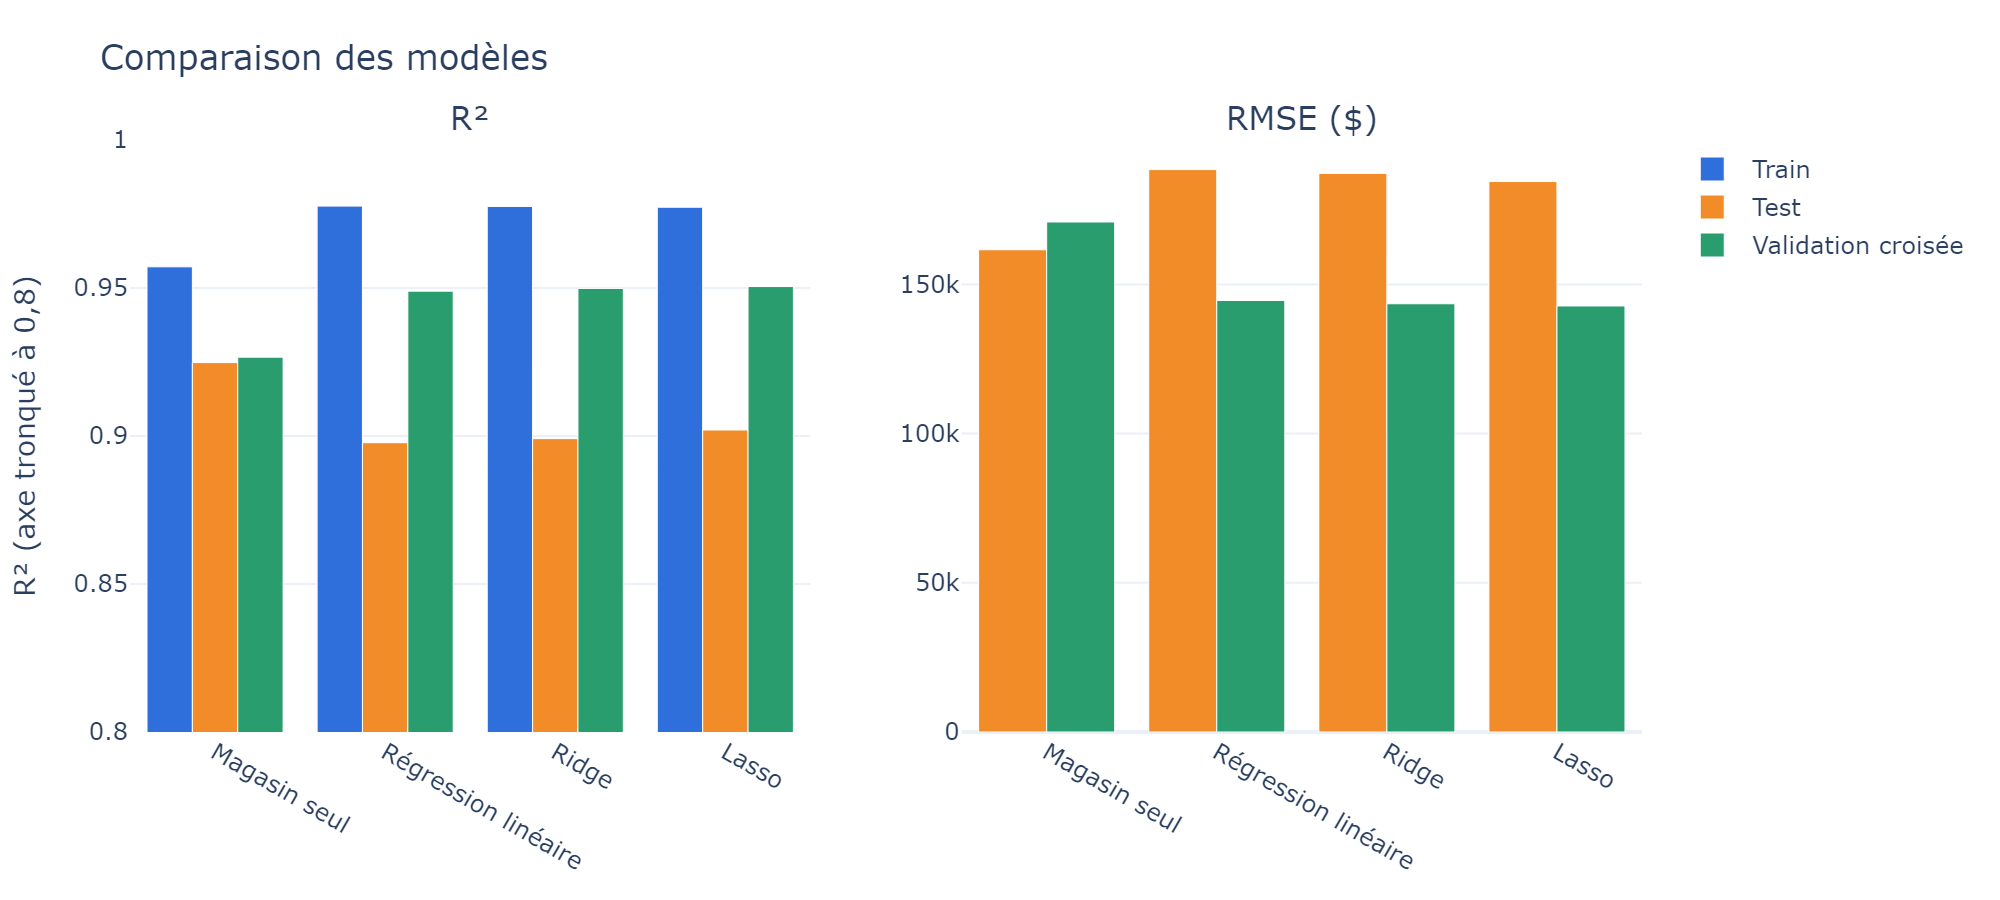

In [127]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("R²", "RMSE ($)"))

for lbl, col, color in [("Train", "R² train", BLUE), ("Test", "R² test", ORANGE), ("Validation croisée", "R² CV", GREEN)]:
    fig.add_trace(go.Bar(name=lbl, x=compared, y=results.loc[compared, col], marker_color=color), row=1, col=1)

for lbl, col, color in [("Test", "RMSE test", ORANGE), ("Validation croisée", "RMSE CV", GREEN)]:
    fig.add_trace(go.Bar(name=lbl, x=compared, y=results.loc[compared, col], marker_color=color, showlegend=False),
                  row=1, col=2)

fig.update_yaxes(range=[0.8, 1], title_text="R² (axe tronqué à 0,8)", row=1, col=1)

fig.update_layout(title="Comparaison des modèles", barmode="group")

show_fig(fig, "fig_12_comparaison_modeles", width=1000)

**Interprétation**
- Les trois modèles linéaires sont à **1,3 % d'écart** en RMSE de validation croisée (144,6, 143,5 et 142,8 k$).
- L'écart entre R² train et test n'est pas réduit (0,978 / 0,898 pour la régression, 0,978 / 0,899 pour Ridge, 0,977 / 0,902 pour Lasso).
- **La régularisation n'apporte presque rien ici : il n'y a pas de gagnant net.** Sur le jeu de test, les trois modèles restent derrière le magasin seul, pour les raisons vues en 3.3 (jeu de test trop petit, une observation extrême).

### 4.3 Effet de la régularisation sur les coefficients

In [128]:
def get_coefs(model):
    return pd.Series(model.named_steps["model"].coef_, index=feature_names(model))

coef_table = pd.DataFrame({"Régression": get_coefs(model_lr),
                           "Ridge": get_coefs(ridge_search.best_estimator_),
                           "Lasso": get_coefs(lasso_search.best_estimator_)})
display(coef_table.round(0))
print(f"Coefficients mis exactement à 0 par le Lasso : {(coef_table['Lasso'] == 0).sum()} sur {len(coef_table)}")

,Régression,Ridge,Lasso
Temperature,-60428.0,-60448.0,-60650.0
Fuel_Price,-7468.0,-6294.0,-7801.0
CPI,48864.0,52336.0,41248.0
Unemployment,-70249.0,-63135.0,-58726.0
Year,-47742.0,-45906.0,-42399.0
Month,67412.0,67506.0,66541.0
Day,-15135.0,-15417.0,-14638.0
Store_2,364779.0,385773.0,377746.0
Store_3,-1203335.0,-1174541.0,-1171889.0
Store_4,575156.0,614307.0,590689.0


Coefficients mis exactement à 0 par le Lasso : 1 sur 26


**Interprétation**  
Les coefficients sont presque identiques d'un modèle à l'autre. Lasso ne réduit à 0 que le coefficient du magasin 19. 

## 5. Conclusion

1. **Le magasin est le premier déterminant des ventes** : une simple moyenne par magasin donne déjà un R² de 0,93 et une erreur relative de 10,9 % sur le test.
2. **La régression linéaire fait mieux en validation croisée** (RMSE −15 %), mais pas de façon systématique : sur 50 découpages, elle gagne 37 fois. Le jeu de test (27 lignes) est trop petit pour trancher.
3. **La régularisation n'apporte presque rien** : régression, Ridge et Lasso sont à 1,3 % d'écart.
4. **Peu de variables explicatives fiables** : température (−), chômage (−) et mois (+). Le CPI et le chômage reflètent surtout le magasin. Ces résultats décrivent des corrélations, pas des causes.
5. **Usage** : le modèle sert à estimer des ventes attendues par magasin, pas à conclure sur l'effet causal des indicateurs économiques.

Récapitulatif de tous les modèles :

In [129]:
display(results.round(ROUND))

,R² train,R² test,R² CV,RMSE train,RMSE test,RMSE CV,MAPE test (%)
Modèle,,,,,,,
Moyenne globale,0.000,-0.032,-0.069,669560.0,598753.0,674237.0,80.0
Magasin seul,0.957,0.925,0.927,138602.0,161621.0,170920.0,10.9
Sans le magasin,0.130,-0.147,-0.172,624677.0,631112.0,701443.0,84.1
Régression linéaire,0.978,0.898,0.949,100071.0,188478.0,144608.0,15.1
Ridge,0.978,0.899,0.950,100347.0,187207.0,143516.0,15.0
Lasso,0.977,0.902,0.950,100915.0,184476.0,142777.0,15.2


## Limites et pistes

- **Très peu d'observations** (131 lignes, 27 en test) : toutes les métriques sont incertaines.
- **Données manquantes** : 12 % des dates sont absentes (imputées) ; le jour du mois est peu pertinent.
- **Dépendance temporelle** : les semaines d'un même magasin ne sont pas indépendantes. Un découpage dans le temps (apprendre sur le passé, tester sur le futur) serait plus réaliste pour une vraie prévision.
- **Magasin 12** : retiré par la règle de l'énoncé ; à discuter avec le métier.
- **Comparaison des modèles réglés** : une validation croisée imbriquée serait plus rigoureuse.
- **Pistes** : plus de données, modèles non linéaires (arbres, forêts aléatoires), variables propres à chaque magasin.